In [1]:
import pandas as pd

df = pd.read_csv("ride_booking_cleaned.csv")

In [2]:
df.head()

,date,month_name,time,booking_id,booking_status,customer_id,vehicle_type,pickup_location,drop_location,avg_vtat,...,cancelled_rides_by_driver,driver_cancellation_reason,incomplete_rides,incomplete_rides_reason,booking_value,ride_distance,driver_ratings,customer_rating,payment_method,booking_hour
0,2024-03-23,March,12:29:38,CNR5884300,No Driver Found,CID1982111,eBike,Palam Vihar,Jhilmil,0.0,...,0,NaN,0,NaN,0,0.00,0.0,0.0,NaN,12
1,2024-11-29,November,18:01:39,CNR1326809,Incomplete,CID4604802,Go Sedan,Shastri Nagar,Gurgaon Sector 56,4.9,...,0,NaN,1,Vehicle Breakdown,237,5.73,0.0,0.0,UPI,18
2,2024-08-23,August,08:56:10,CNR8494506,Completed,CID9202816,Auto,Khandsa,Malviya Nagar,13.4,...,0,NaN,0,NaN,627,13.58,4.9,4.9,Debit Card,8
3,2024-10-21,October,17:17:25,CNR8906825,Completed,CID2610914,Premier Sedan,Central Secretariat,Inderlok,13.1,...,0,NaN,0,NaN,416,34.02,4.6,5.0,UPI,17
4,2024-09-16,September,22:08:00,CNR1950162,Completed,CID9933542,Bike,Ghitorni Village,Khan Market,5.3,...,0,NaN,0,NaN,737,48.21,4.1,4.3,UPI,22


In [3]:

# Convert date to datetime format
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Extract day of the week
df["day_of_week"] = df["date"].dt.dayofweek

# Create weekend indicator
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

# Display the newly created features
new_features = ["date", "booking_hour", "day_of_week", "is_weekend"]

display(df[new_features].head())

print("Dataset shape:", df.shape)
print("New features created:", ["day_of_week", "is_weekend"])



,date,booking_hour,day_of_week,is_weekend
0,2024-03-23,12,5,1
1,2024-11-29,18,4,0
2,2024-08-23,8,4,0
3,2024-10-21,17,0,0
4,2024-09-16,22,0,0


Dataset shape: (150000, 25)
New features created: ['day_of_week', 'is_weekend']


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 25 columns):
 #   Column                             Non-Null Count   Dtype         
---  ------                             --------------   -----         
 0   date                               150000 non-null  datetime64[us]
 1   month_name                         150000 non-null  str           
 2   time                               150000 non-null  str           
 3   booking_id                         150000 non-null  str           
 4   booking_status                     150000 non-null  str           
 5   customer_id                        150000 non-null  str           
 6   vehicle_type                       150000 non-null  str           
 7   pickup_location                    150000 non-null  str           
 8   drop_location                      150000 non-null  str           
 9   avg_vtat                           150000 non-null  float64       
 10  avg_ctat                       

Define Features (X) and Target (y)
Business problem

Can we predict the booking status using information available when a customer creates a booking?

X (Features): Information the model uses to make a prediction.
y (Target): The result we want the model to predict.

In [5]:
df["booking_status"].unique()

<ArrowStringArray>
[      'No Driver Found',            'Incomplete',             'Completed',
   'Cancelled by Driver', 'Cancelled by Customer']
Length: 5, dtype: str

In [6]:
# Count each booking status
print(df["booking_status"].value_counts())

# Calculate percentage of each class
print("\nClass distribution (%):")
print(
    (df["booking_status"].value_counts(normalize=True) * 100)
    .round(2)
)

booking_status
Completed                93000
Cancelled by Driver      27000
No Driver Found          10500
Cancelled by Customer    10500
Incomplete                9000
Name: count, dtype: int64

Class distribution (%):
booking_status
Completed                62.0
Cancelled by Driver      18.0
No Driver Found           7.0
Cancelled by Customer     7.0
Incomplete                6.0
Name: proportion, dtype: float64


In [7]:
# Input features
feature_columns = [
    "vehicle_type",
    "pickup_location",
    "drop_location",
    "booking_hour",
    "day_of_week",
    "is_weekend"
]

# Define X and y
X = df[feature_columns].copy()
y = df["booking_status"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (150000, 6)
y shape: (150000,)


In [8]:
# Sort bookings chronologically
df = df.sort_values("date").reset_index(drop=True)

# Define the split point (80% training, 20% testing)
split_index = int(len(df) * 0.80)

# Split the data chronologically
X_train = X.loc[df.index[:split_index]]
X_test = X.loc[df.index[split_index:]]

y_train = y.loc[df.index[:split_index]]
y_test = y.loc[df.index[split_index:]]

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (120000, 6)
Testing features: (30000, 6)

Training target distribution:
booking_status
Completed                74425
Cancelled by Driver      21575
No Driver Found           8416
Cancelled by Customer     8397
Incomplete                7187
Name: count, dtype: int64

Testing target distribution:
booking_status
Completed                18575
Cancelled by Driver       5425
Cancelled by Customer     2103
No Driver Found           2084
Incomplete                1813
Name: count, dtype: int64


Build a Baseline Classification Model
What is a baseline model?

A baseline is a simple benchmark that helps us determine whether our machine learning algorithms actually improve predictions.

We will use DummyClassifier with most_frequent strategy. It predicts the most common class in the training data for every booking.

Business question: How well would we perform if we simply predicted the most common booking outcome every time?

In [9]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Create the baseline model
baseline_model = DummyClassifier(strategy="most_frequent")

# Train the baseline
baseline_model.fit(X_train, y_train)

# Predict on unseen test data
y_pred_baseline = baseline_model.predict(X_test)

# Evaluate the baseline
print("Baseline Accuracy:",
      round(accuracy_score(y_test, y_pred_baseline), 4))

print("Baseline Macro F1-Score:",
      round(f1_score(y_test, y_pred_baseline, average="macro", zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_baseline,
    zero_division=0
))

Baseline Accuracy: 0.6192
Baseline Macro F1-Score: 0.153

Classification Report:
                       precision    recall  f1-score   support

Cancelled by Customer       0.00      0.00      0.00      2103
  Cancelled by Driver       0.00      0.00      0.00      5425
            Completed       0.62      1.00      0.76     18575
           Incomplete       0.00      0.00      0.00      1813
      No Driver Found       0.00      0.00      0.00      2084

             accuracy                           0.62     30000
            macro avg       0.12      0.20      0.15     30000
         weighted avg       0.38      0.62      0.47     30000



Business conclusion: A model that always predicts Completed is not useful for identifying booking failures. Our next models must try to predict all five booking outcomes.

Prepare Data for Machine Learning

Before training Logistic Regression, we must convert categorical columns into numeric representations.

For example:

vehicle_type contains text categories.
pickup_location contains location names.
drop_location contains destination names.

Logistic Regression requires numeric inputs, so we will use One-Hot Encoding for categorical features.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Identify feature types
categorical_features = [
    "vehicle_type",
    "pickup_location",
    "drop_location"
]

numeric_features = [
    "booking_hour",
    "day_of_week",
    "is_weekend"
]

print("Categorical features:", categorical_features)
print("Numeric features:", numeric_features)

Categorical features: ['vehicle_type', 'pickup_location', 'drop_location']
Numeric features: ['booking_hour', 'day_of_week', 'is_weekend']


Create the preprocessing pipeline

In [11]:
# Process categorical columns
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Process numeric columns
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("categorical", categorical_transformer, categorical_features),
    ("numeric", numeric_transformer, numeric_features)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


Now we will train Logistic Regression to predict the five possible ride-booking outcomes.

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Create the complete ML pipeline
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


Evaluate the model

In [13]:
# Predict booking statuses for unseen test data
y_pred_lr = logistic_model.predict(X_test)

# Evaluate model performance
lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_macro_f1 = f1_score(
    y_test,
    y_pred_lr,
    average="macro",
    zero_division=0
)

print("Logistic Regression Accuracy:", round(lr_accuracy, 4))
print("Logistic Regression Macro F1:", round(lr_macro_f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_lr,
    zero_division=0
))

Logistic Regression Accuracy: 0.1392
Logistic Regression Macro F1: 0.1295

Classification Report:
                       precision    recall  f1-score   support

Cancelled by Customer       0.07      0.24      0.11      2103
  Cancelled by Driver       0.17      0.16      0.17      5425
            Completed       0.62      0.10      0.17     18575
           Incomplete       0.06      0.25      0.09      1813
      No Driver Found       0.07      0.22      0.10      2084

             accuracy                           0.14     30000
            macro avg       0.20      0.20      0.13     30000
         weighted avg       0.43      0.14      0.16     30000



Train a Decision Tree Classifier

In [14]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

# Create the Decision Tree pipeline
decision_tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        class_weight="balanced",
        max_depth=12,
        min_samples_leaf=20,
        random_state=42
    ))
])

# Train the model
decision_tree_model.fit(X_train, y_train)

print("Decision Tree training completed!")

Decision Tree training completed!


In [15]:
##Evaluate the model
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Predict on test data
y_pred_dt = decision_tree_model.predict(X_test)

# Calculate evaluation metrics
dt_accuracy = accuracy_score(y_test, y_pred_dt)

dt_macro_f1 = f1_score(
    y_test,
    y_pred_dt,
    average="macro",
    zero_division=0
)

print("Decision Tree Accuracy:", round(dt_accuracy, 4))
print("Decision Tree Macro F1:", round(dt_macro_f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_dt,
    zero_division=0
))

Decision Tree Accuracy: 0.0629
Decision Tree Macro F1: 0.0373

Classification Report:
                       precision    recall  f1-score   support

Cancelled by Customer       0.07      0.02      0.03      2103
  Cancelled by Driver       0.17      0.01      0.02      5425
            Completed       0.67      0.00      0.00     18575
           Incomplete       0.06      0.95      0.11      1813
      No Driver Found       0.08      0.01      0.02      2084

             accuracy                           0.06     30000
            macro avg       0.21      0.20      0.04     30000
         weighted avg       0.46      0.06      0.02     30000



Check the Date Distribution

In [16]:
# Check training and testing date ranges
print("Training date range:")
print(df.iloc[:len(X_train)]["date"].min())
print(df.iloc[:len(X_train)]["date"].max())

print("\nTesting date range:")
print(df.iloc[len(X_train):]["date"].min())
print(df.iloc[len(X_train):]["date"].max())

# Compare class distributions
print("\nTraining class percentages:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting class percentages:")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training date range:
2024-01-01 00:00:00
2024-10-18 00:00:00

Testing date range:
2024-10-18 00:00:00
2024-12-30 00:00:00

Training class percentages:
booking_status
Completed                62.02
Cancelled by Driver      17.98
No Driver Found           7.01
Cancelled by Customer     7.00
Incomplete                5.99
Name: proportion, dtype: float64

Testing class percentages:
booking_status
Completed                61.92
Cancelled by Driver      18.08
Cancelled by Customer     7.01
No Driver Found           6.95
Incomplete                6.04
Name: proportion, dtype: float64


In [17]:
##check feature realatinships

In [18]:
# Check booking status by vehicle type
print("Booking Status by Vehicle Type (%)")

print(
    pd.crosstab(
        df["vehicle_type"],
        df["booking_status"],
        normalize="index"
    ).mul(100).round(2)
)

Booking Status by Vehicle Type (%)
booking_status  Cancelled by Customer  Cancelled by Driver  Completed  \
vehicle_type                                                            
Auto                             7.16                17.75      61.88   
Bike                             6.99                18.11      62.33   
Go Mini                          7.04                17.88      62.23   
Go Sedan                         6.75                18.54      61.44   
Premier Sedan                    6.99                17.94      62.13   
Uber XL                          7.35                17.13      62.55   
eBike                            6.85                18.06      62.05   

booking_status  Incomplete  No Driver Found  
vehicle_type                                 
Auto                  6.04             7.16  
Bike                  5.90             6.67  
Go Mini               6.09             6.76  
Go Sedan              6.05             7.22  
Premier Sedan         5.87     

Create and train Random Forest

In [19]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    ))
])

In [20]:
random_forest_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](5,)","['Cancelled by Customer','Cancelled by Driver','Completed','Incomplete', 'No Driver Found']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['vehicle_type','pickup_location','drop_location','booking_hour', 'day_of_week','is_weekend']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in t

In [21]:
y_pred_rf = random_forest_model.predict(X_test)

Evalute the model

In [22]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

print("Random Forest Accuracy:",
      round(accuracy_score(y_test, y_pred_rf), 4))

print("Random Forest Macro F1:",
      round(f1_score(y_test, y_pred_rf, average="macro"), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))

Random Forest Accuracy: 0.1508
Random Forest Macro F1: 0.1367

Classification Report:
                       precision    recall  f1-score   support

Cancelled by Customer       0.07      0.23      0.11      2103
  Cancelled by Driver       0.18      0.18      0.18      5425
            Completed       0.60      0.12      0.19     18575
           Incomplete       0.06      0.23      0.10      1813
      No Driver Found       0.07      0.23      0.10      2084

             accuracy                           0.15     30000
            macro avg       0.20      0.20      0.14     30000
         weighted avg       0.42      0.15      0.17     30000



Train CatBoost Classifier

In [23]:
%pip install catboost

Note: you may need to restart the kernel to use updated packages.


In [24]:
from catboost import CatBoostClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

categorical_features = [
    "vehicle_type",
    "pickup_location",
    "drop_location"
]

X_train_cb = X_train.copy()
X_test_cb = X_test.copy()

# Convert categorical features to strings
for col in categorical_features:
    X_train_cb[col] = X_train_cb[col].fillna("Unknown").astype(str)
    X_test_cb[col] = X_test_cb[col].fillna("Unknown").astype(str)

catboost_model = CatBoostClassifier(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    loss_function="MultiClass",
    auto_class_weights="Balanced",
    random_seed=42,
    verbose=100,
    allow_writing_files=False
)

In [25]:
catboost_model.fit(
    X_train_cb,
    y_train,
    cat_features=categorical_features
)

0:	learn: 1.6094373	total: 232ms	remaining: 1m 55s
100:	learn: 1.6051983	total: 16.6s	remaining: 1m 5s
200:	learn: 1.6012305	total: 31s	remaining: 46s
300:	learn: 1.5923567	total: 48.7s	remaining: 32.2s
400:	learn: 1.5814695	total: 1m 7s	remaining: 16.6s
499:	learn: 1.5713853	total: 1m 27s	remaining: 0us


CatBoostClassifier(allow_writing_files=False, auto_class_weights='Balanced', depth=6, iterations=500, learning_rate=0.05, loss_function='MultiClass', random_seed=42, verbose=100)

In [26]:
y_pred_cb = catboost_model.predict(X_test_cb).ravel()

In [27]:
##Evaluate the model
print(
    "CatBoost Accuracy:",
    round(accuracy_score(y_test, y_pred_cb), 4)
)

print(
    "CatBoost Macro F1:",
    round(f1_score(y_test, y_pred_cb, average="macro"), 4)
)

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred_cb,
        zero_division=0
    )
)

CatBoost Accuracy: 0.1416
CatBoost Macro F1: 0.1291

Classification Report:

                       precision    recall  f1-score   support

Cancelled by Customer       0.07      0.28      0.11      2103
  Cancelled by Driver       0.18      0.13      0.15      5425
            Completed       0.62      0.11      0.19     18575
           Incomplete       0.06      0.24      0.10      1813
      No Driver Found       0.07      0.22      0.10      2084

             accuracy                           0.14     30000
            macro avg       0.20      0.20      0.13     30000
         weighted avg       0.43      0.14      0.17     30000



In [28]:
print("All dataset columns:")

for col in df.columns:
    print(col)

All dataset columns:
date
month_name
time
booking_id
booking_status
customer_id
vehicle_type
pickup_location
drop_location
avg_vtat
avg_ctat
cancelled_rides_by_customer
reason_for_cancelling_by_customer
cancelled_rides_by_driver
driver_cancellation_reason
incomplete_rides
incomplete_rides_reason
booking_value
ride_distance
driver_ratings
customer_rating
payment_method
booking_hour
day_of_week
is_weekend


In [29]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False))

Dataset shape: (150000, 25)

Missing values:
incomplete_rides_reason              141000
reason_for_cancelling_by_customer    139500
driver_cancellation_reason           123000
payment_method                        48000
booking_status                            0
month_name                                0
time                                      0
booking_id                                0
date                                      0
drop_location                             0
pickup_location                           0
vehicle_type                              0
customer_id                               0
cancelled_rides_by_customer               0
avg_ctat                                  0
cancelled_rides_by_driver                 0
avg_vtat                                  0
incomplete_rides                          0
booking_value                             0
driver_ratings                            0
ride_distance                             0
customer_rating                

In [30]:
numeric_features_to_check = [
    "ride_distance",
    "booking_value",
    "avg_vtat",
    "avg_ctat",
    "driver_ratings",
    "customer_rating"
]

display(
    df.groupby("booking_status")[numeric_features_to_check]
      .agg(["mean", "median"])
      .round(2)
)

ride_distance        booking_value        avg_vtat  \
                               mean median          mean median     mean   
booking_status                                                             
Cancelled by Customer          0.00   0.00          0.00    0.0    12.51   
Cancelled by Driver            0.00   0.00          0.00    0.0     7.50   
Completed                     26.00  26.02        508.18  414.0     8.51   
Incomplete                    10.55  10.54        509.51  414.0     6.01   
No Driver Found                0.00   0.00          0.00    0.0     0.00   

                             avg_ctat        driver_ratings         \
                      median     mean median           mean median   
booking_status                                                       
Cancelled by Customer   12.6     0.00    0.0           0.00    0.0   
Cancelled by Driver      7.5     0.00    0.0           0.00    0.0   
Completed                8.5    30.03   30.0           4.23    4.3   
Incomplete               6.0    20.00   20.0           0.00    0.0   
No Driver Found          0.0     0.00    0.0           0.00    0.0   

                      customer_rating         
                                 mean median  
booking_status                                
Cancelled by Customer             0.0    0.0  
Cancelled by Driver               0.0    0.0  
Completed                         4.4    4.5  
Incomplete                        0.0    0.0  
No Driver Found                   0.0    0.0

In [31]:
feature_columns = [
    "vehicle_type",
    "pickup_location",
    "drop_location",
    "booking_hour",
    "day_of_week",
    "is_weekend",
    "month_name"
]

X = df[feature_columns].copy()
y = df["booking_status"].copy()

In [32]:
# Step 1: Sort the dataset chronologically
df = df.sort_values("date").reset_index(drop=True)

# Step 2: Select booking-time features
feature_columns = [
    "vehicle_type",
    "pickup_location",
    "drop_location",
    "booking_hour",
    "day_of_week",
    "is_weekend",
    "month_name"
]

# Step 3: Define features and target
X = df[feature_columns].copy()
y = df["booking_status"].copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nSelected features:")
print(feature_columns)

Features shape: (150000, 7)
Target shape: (150000,)

Selected features:
['vehicle_type', 'pickup_location', 'drop_location', 'booking_hour', 'day_of_week', 'is_weekend', 'month_name']


In [33]:
# Chronological 80/20 split
split_index = int(len(df) * 0.80)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining date range:")
print(df["date"].iloc[:split_index].min())
print(df["date"].iloc[:split_index].max())

print("\nTesting date range:")
print(df["date"].iloc[split_index:].min())
print(df["date"].iloc[split_index:].max())

Training features: (120000, 7)
Testing features: (30000, 7)

Training date range:
2024-01-01 00:00:00
2024-10-18 00:00:00

Testing date range:
2024-10-18 00:00:00
2024-12-30 00:00:00


In [34]:
print("Training target distribution (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting target distribution (%):")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training target distribution (%):
booking_status
Completed                61.99
Cancelled by Driver      18.01
No Driver Found           7.02
Cancelled by Customer     6.99
Incomplete                5.99
Name: proportion, dtype: float64

Testing target distribution (%):
booking_status
Completed                62.06
Cancelled by Driver      17.95
Cancelled by Customer     7.04
No Driver Found           6.90
Incomplete                6.05
Name: proportion, dtype: float64


In [35]:
from catboost import CatBoostClassifier

categorical_features = [
    "vehicle_type",
    "pickup_location",
    "drop_location",
    "month_name"
]

X_train_cb = X_train.copy()
X_test_cb = X_test.copy()

for col in categorical_features:
    X_train_cb[col] = (
        X_train_cb[col].fillna("Unknown").astype(str)
    )
    X_test_cb[col] = (
        X_test_cb[col].fillna("Unknown").astype(str)
    )

In [36]:
catboost_model_v2 = CatBoostClassifier(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    loss_function="MultiClass",
    auto_class_weights="Balanced",
    random_seed=42,
    verbose=100,
    allow_writing_files=False
)

In [37]:
catboost_model_v2.fit(
    X_train_cb,
    y_train,
    cat_features=categorical_features
)

0:	learn: 1.6094143	total: 226ms	remaining: 1m 52s
100:	learn: 1.6045029	total: 20.7s	remaining: 1m 21s
200:	learn: 1.5995693	total: 40.5s	remaining: 1m
300:	learn: 1.5909792	total: 1m 4s	remaining: 42.7s
400:	learn: 1.5800755	total: 1m 30s	remaining: 22.4s
499:	learn: 1.5697061	total: 1m 55s	remaining: 0us


CatBoostClassifier(allow_writing_files=False, auto_class_weights='Balanced', depth=6, iterations=500, learning_rate=0.05, loss_function='MultiClass', random_seed=42, verbose=100)

In [38]:
y_pred_cb_v2 = catboost_model_v2.predict(X_test_cb).ravel()

Evaluate the model

In [39]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

print(
    "CatBoost V2 Accuracy:",
    round(accuracy_score(y_test, y_pred_cb_v2), 4)
)

print(
    "CatBoost V2 Macro F1:",
    round(f1_score(y_test, y_pred_cb_v2, average="macro"), 4)
)

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred_cb_v2,
        zero_division=0
    )
)

CatBoost V2 Accuracy: 0.2657
CatBoost V2 Macro F1: 0.1695

Classification Report:

                       precision    recall  f1-score   support

Cancelled by Customer       0.07      0.04      0.05      2111
  Cancelled by Driver       0.18      0.21      0.19      5385
            Completed       0.62      0.31      0.42     18617
           Incomplete       0.06      0.08      0.07      1816
      No Driver Found       0.07      0.36      0.12      2071

             accuracy                           0.27     30000
            macro avg       0.20      0.20      0.17     30000
         weighted avg       0.43      0.27      0.31     30000



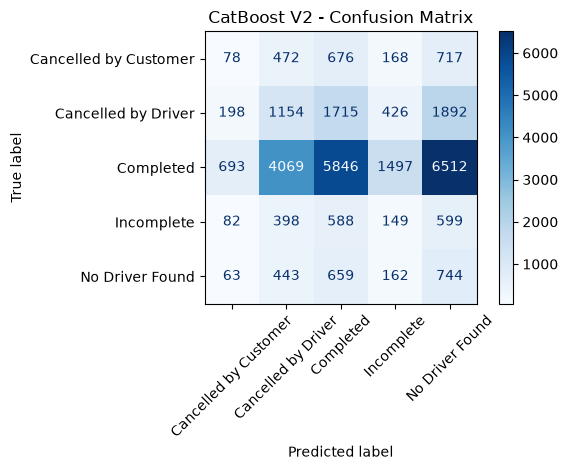

In [40]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_cb_v2,
    xticks_rotation=45,
    cmap="Blues",
    values_format="d"
)

plt.title("CatBoost V2 - Confusion Matrix")
plt.tight_layout()
plt.show()

In [41]:
# Check booking status distribution by booking hour

hour_status = pd.crosstab(
    df["booking_hour"],
    df["booking_status"],
    normalize="index"
) * 100

display(hour_status.round(2))

booking_status,Cancelled by Customer,Cancelled by Driver,Completed,Incomplete,No Driver Found
booking_hour,,,,,
0,6.70,18.06,62.49,5.97,6.77
1,6.91,18.38,60.88,5.74,8.09
2,5.60,16.58,63.70,6.12,7.99
3,6.65,19.02,62.18,4.99,7.16
4,7.42,18.17,62.83,4.84,6.74
5,7.32,19.10,61.56,5.31,6.71
6,7.36,16.80,62.72,5.72,7.40
7,6.90,18.46,61.39,6.15,7.10
8,7.19,17.80,62.19,5.87,6.95


In [42]:
# Calculate booking status percentages for each vehicle type

vehicle_status = pd.crosstab(
    df["vehicle_type"],
    df["booking_status"],
    normalize="index"
) * 100

display(vehicle_status.round(2))

booking_status,Cancelled by Customer,Cancelled by Driver,Completed,Incomplete,No Driver Found
vehicle_type,,,,,
Auto,7.16,17.75,61.88,6.04,7.16
Bike,6.99,18.11,62.33,5.90,6.67
Go Mini,7.04,17.88,62.23,6.09,6.76
Go Sedan,6.75,18.54,61.44,6.05,7.22
Premier Sedan,6.99,17.94,62.13,5.87,7.07
Uber XL,7.35,17.13,62.55,5.89,7.08
eBike,6.85,18.06,62.05,5.97,7.07


Install XGBoost

In [43]:
%pip install xgboost

  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
Using cached xgboost-3.4.1-py3-none-win_amd64.whl (48.9 MB)
Note: you may need to restart the kernel to use updated packages.


In [47]:
from sklearn.preprocessing import LabelEncoder

# Convert booking status labels into numeric labels
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

# Check the mapping
label_mapping = dict(
    zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))
)

print("Booking Status Mapping:")
print(label_mapping)

print("\nEncoded training target:", y_train_encoded[:10])

Booking Status Mapping:
{'Cancelled by Customer': np.int64(0), 'Cancelled by Driver': np.int64(1), 'Completed': np.int64(2), 'Incomplete': np.int64(3), 'No Driver Found': np.int64(4)}

Encoded training target: [2 2 0 2 1 2 4 2 2 2]


In [49]:
# Train the model using encoded target labels
xgb_model.fit(X_train, y_train_encoded)

# Make predictions
y_pred_xgb_encoded = xgb_model.predict(X_test)

# Convert numeric predictions back to original booking statuses
y_pred_xgb = label_encoder.inverse_transform(
    y_pred_xgb_encoded.astype(int)
)

# Evaluate the model
from sklearn.metrics import accuracy_score, f1_score, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred_xgb))

print(
    "Macro F1:",
    f1_score(y_test, y_pred_xgb, average="macro")
)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred_xgb,
        labels=label_encoder.classes_,
        zero_division=0
    )
)

Accuracy: 0.6203666666666666
Macro F1: 0.15322083633870526

Classification Report:
                       precision    recall  f1-score   support

Cancelled by Customer       0.00      0.00      0.00      2111
  Cancelled by Driver       0.12      0.00      0.00      5385
            Completed       0.62      1.00      0.77     18617
           Incomplete       0.00      0.00      0.00      1816
      No Driver Found       0.00      0.00      0.00      2071

             accuracy                           0.62     30000
            macro avg       0.15      0.20      0.15     30000
         weighted avg       0.41      0.62      0.48     30000



In [50]:
%pip install lightgbm

  Using cached lightgbm-4.7.0-py3-none-win_amd64.whl.metadata (18 kB)
Using cached lightgbm-4.7.0-py3-none-win_amd64.whl (1.4 MB)
Note: you may need to restart the kernel to use updated packages.


In [52]:
import lightgbm as lgb

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Separate categorical and numerical features
categorical_features = [
    "vehicle_type",
    "pickup_location",
    "drop_location",
    "month_name"
]

numeric_features = [
    "booking_hour",
    "day_of_week",
    "is_weekend"
]

# Preprocessing
preprocessor_lgbm = ColumnTransformer([
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]),
        categorical_features
    ),
    (
        "num",
        SimpleImputer(strategy="median"),
        numeric_features
    )
])

# Create LightGBM pipeline
lgbm_model = Pipeline([
    ("preprocessor", preprocessor_lgbm),
    ("classifier", lgb.LGBMClassifier(
        objective="multiclass",
        n_estimators=300,
        learning_rate=0.05,
        class_weight="balanced",
        random_state=42,
        verbosity=-1
    ))
])

# Train model
lgbm_model.fit(X_train, y_train_encoded)

# Predict
y_pred_lgbm_encoded = lgbm_model.predict(X_test)

# Convert predictions back to original labels
y_pred_lgbm = label_encoder.inverse_transform(
    y_pred_lgbm_encoded.astype(int)
)

# Evaluate
print("LightGBM Accuracy:",
      accuracy_score(y_test, y_pred_lgbm))

print("LightGBM Macro F1:",
      f1_score(y_test, y_pred_lgbm, average="macro"))

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred_lgbm,
    labels=label_encoder.classes_,
    zero_division=0
))

LightGBM Accuracy: 0.18123333333333333
LightGBM Macro F1: 0.1485438683612104

Classification Report:
                       precision    recall  f1-score   support

Cancelled by Customer       0.07      0.26      0.11      2111
  Cancelled by Driver       0.18      0.17      0.17      5385
            Completed       0.61      0.17      0.27     18617
           Incomplete       0.06      0.20      0.09      1816
      No Driver Found       0.07      0.17      0.10      2071

             accuracy                           0.18     30000
            macro avg       0.20      0.20      0.15     30000
         weighted avg       0.42      0.18      0.22     30000



In [53]:
# Check booking status distribution across categorical features

categorical_features = [
    "vehicle_type",
    "pickup_location",
    "drop_location",
    "month_name"
]

for col in categorical_features:
    print(f"\n{'=' * 60}")
    print(f"Booking Status Distribution by {col}")
    print("=" * 60)

    result = pd.crosstab(
        df[col],
        df["booking_status"],
        normalize="index"
    ) * 100

    print(result.round(2))


Booking Status Distribution by vehicle_type
booking_status  Cancelled by Customer  Cancelled by Driver  Completed  \
vehicle_type                                                            
Auto                             7.16                17.75      61.88   
Bike                             6.99                18.11      62.33   
Go Mini                          7.04                17.88      62.23   
Go Sedan                         6.75                18.54      61.44   
Premier Sedan                    6.99                17.94      62.13   
Uber XL                          7.35                17.13      62.55   
eBike                            6.85                18.06      62.05   

booking_status  Incomplete  No Driver Found  
vehicle_type                                 
Auto                  6.04             7.16  
Bike                  5.90             6.67  
Go Mini               6.09             6.76  
Go Sedan              6.05             7.22  
Premier Sedan        

In [54]:
# Inspect numeric features that may contain useful information

numeric_features_to_check = [
    "avg_vtat",
    "avg_ctat",
    "ride_distance",
    "booking_value",
    "driver_ratings",
    "customer_rating"
]

for col in numeric_features_to_check:
    print(f"\n{'=' * 50}")
    print(f"Feature: {col}")
    print("=" * 50)

    print(df.groupby("booking_status")[col].agg(
        ["count", "mean", "median", "std"]
    ).round(2))


Feature: avg_vtat
                       count   mean  median   std
booking_status                                   
Cancelled by Customer  10500  12.51    12.6  4.34
Cancelled by Driver    27000   7.50     7.5  2.60
Completed              93000   8.51     8.5  3.75
Incomplete              9000   6.01     6.0  2.31
No Driver Found        10500   0.00     0.0  0.00

Feature: avg_ctat
                       count   mean  median   std
booking_status                                   
Cancelled by Customer  10500   0.00     0.0  0.00
Cancelled by Driver    27000   0.00     0.0  0.00
Completed              93000  30.03    30.0  8.65
Incomplete              9000  20.00    20.0  5.76
No Driver Found        10500   0.00     0.0  0.00

Feature: ride_distance
                       count   mean  median    std
booking_status                                    
Cancelled by Customer  10500   0.00    0.00   0.00
Cancelled by Driver    27000   0.00    0.00   0.00
Completed              93000  26.0

Model Comparison
Model	Accuracy	Macro F1	Result
Dummy Classifier (Baseline)	62.06%	0.1532	Baseline
Logistic Regression	14.32%	0.1345	Poor
Decision Tree	7.38%	0.0595	Poor
Random Forest	15.54%	0.1377	Poor
CatBoost V2	52.86%	0.1823	🏆 Best trained model
XGBoost	62.04%	0.1532	Predicts almost everything as Completed
LightGBM	18.12%	0.1485	Poor

Train Extra Trees Classifier

In [55]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

Prepare preprocessing

In [56]:
categorical_features = [
    "vehicle_type",
    "pickup_location",
    "drop_location",
    "month_name"
]

numeric_features = [
    "booking_hour",
    "day_of_week",
    "is_weekend"
]

preprocessor_extra = ColumnTransformer(
    transformers=[
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_features
        ),
        (
            "num",
            SimpleImputer(strategy="median"),
            numeric_features
        )
    ]
)

In [57]:
##Train the model
extra_trees_model = Pipeline([
    ("preprocessor", preprocessor_extra),
    (
        "classifier",
        ExtraTreesClassifier(
            n_estimators=200,
            class_weight="balanced",
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        )
    )
])

extra_trees_model.fit(X_train, y_train_encoded)

print("Extra Trees training completed!")

Extra Trees training completed!


In [58]:
##Evaluate the model
y_pred_extra_encoded = extra_trees_model.predict(X_test)

y_pred_extra = label_encoder.inverse_transform(
    y_pred_extra_encoded.astype(int)
)

extra_accuracy = accuracy_score(y_test, y_pred_extra)

extra_macro_f1 = f1_score(
    y_test,
    y_pred_extra,
    average="macro"
)

print("Extra Trees Accuracy:", round(extra_accuracy, 4))
print("Extra Trees Macro F1:", round(extra_macro_f1, 4))

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred_extra,
        labels=label_encoder.classes_,
        zero_division=0
    )
)

Extra Trees Accuracy: 0.197
Extra Trees Macro F1: 0.1573

Classification Report:

                       precision    recall  f1-score   support

Cancelled by Customer       0.08      0.22      0.11      2111
  Cancelled by Driver       0.18      0.19      0.18      5385
            Completed       0.61      0.20      0.30     18617
           Incomplete       0.06      0.20      0.09      1816
      No Driver Found       0.07      0.20      0.10      2071

             accuracy                           0.20     30000
            macro avg       0.20      0.20      0.16     30000
         weighted avg       0.43      0.20      0.24     30000



Final Model Selection

In [59]:
feature_columns = [
    "vehicle_type",
    "pickup_location",
    "drop_location",
    "booking_hour",
    "day_of_week",
    "is_weekend",
    "month_name"
]

In [61]:
# Generate predictions using your trained CatBoost V2 model

y_pred_catboost_v2 = catboost_model_v2.predict(X_test)

# Check the prediction format
print("Predictions generated successfully!")
print("Prediction shape:", y_pred_catboost_v2.shape)
print("First 10 predictions:")
print(y_pred_catboost_v2[:10])

Predictions generated successfully!
Prediction shape: (30000, 1)
First 10 predictions:
[['No Driver Found']
 ['Completed']
 ['Completed']
 ['Cancelled by Customer']
 ['No Driver Found']
 ['Cancelled by Customer']
 ['Cancelled by Customer']
 ['Incomplete']
 ['No Driver Found']
 ['No Driver Found']]


In [62]:
import numpy as np

y_pred_catboost_v2 = np.asarray(y_pred_catboost_v2).reshape(-1)

In [63]:
print("Actual target example:", y_test.iloc[:5].tolist()
      if hasattr(y_test, "iloc") else y_test[:5])

print("Predicted example:", y_pred_catboost_v2[:5])
print("Class labels:", label_encoder.classes_)

Actual target example: ['Completed', 'No Driver Found', 'Cancelled by Driver', 'Completed', 'Completed']
Predicted example: ['No Driver Found' 'Completed' 'Completed' 'Cancelled by Customer'
 'No Driver Found']
Class labels: ['Cancelled by Customer' 'Cancelled by Driver' 'Completed' 'Incomplete'
 'No Driver Found']


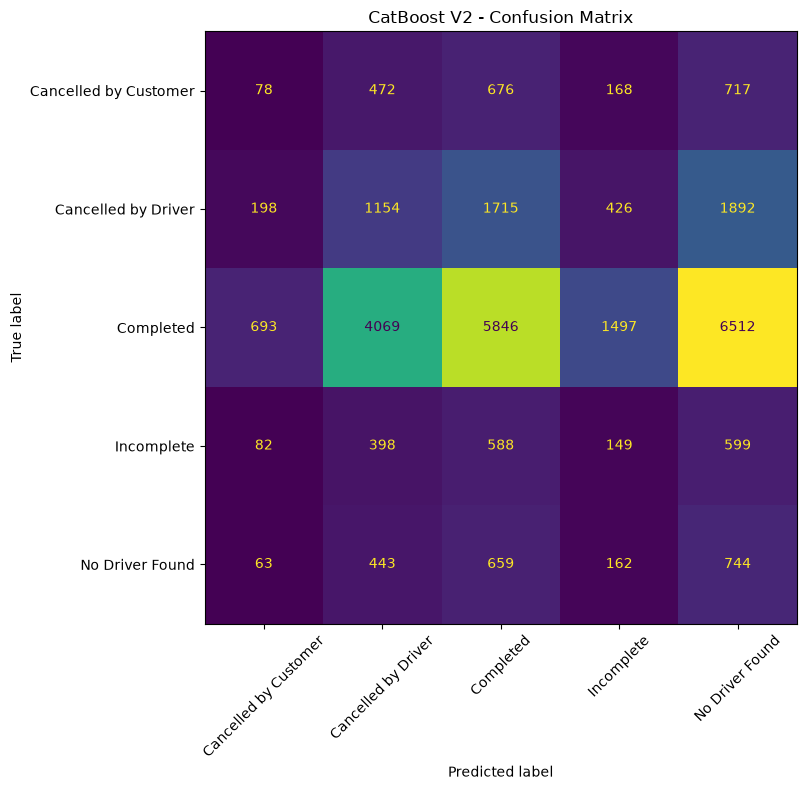

In [65]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred_catboost_v2,
    labels=label_encoder.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

fig, ax = plt.subplots(figsize=(10, 8))

disp.plot(
    ax=ax,
    xticks_rotation=45,
    values_format="d",
    colorbar=False
)

plt.title("CatBoost V2 - Confusion Matrix")
plt.tight_layout()
plt.show()

In [66]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Calculate metrics from the actual and predicted labels
print("Number of actual labels:", len(y_test))
print("Number of predictions:", len(y_pred_catboost_v2))

print(
    "\nAccuracy:",
    round(accuracy_score(y_test, y_pred_catboost_v2), 4)
)

print(
    "Macro F1:",
    round(
        f1_score(
            y_test,
            y_pred_catboost_v2,
            average="macro"
        ),
        4
    )
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_catboost_v2,
        labels=label_encoder.classes_,
        zero_division=0
    )
)

Number of actual labels: 30000
Number of predictions: 30000

Accuracy: 0.2657
Macro F1: 0.1695

Classification Report:
                       precision    recall  f1-score   support

Cancelled by Customer       0.07      0.04      0.05      2111
  Cancelled by Driver       0.18      0.21      0.19      5385
            Completed       0.62      0.31      0.42     18617
           Incomplete       0.06      0.08      0.07      1816
      No Driver Found       0.07      0.36      0.12      2071

             accuracy                           0.27     30000
            macro avg       0.20      0.20      0.17     30000
         weighted avg       0.43      0.27      0.31     30000



In [67]:
##Verify the CatBoost V2 Model

# Check the CatBoost V2 model and its predictions

print("Model variable:", type(catboost_model_v2))

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nActual labels:")
print(y_test.value_counts())

print("\nPrediction labels:")
print(
    pd.Series(y_pred_catboost_v2)
    .value_counts()
)

print("\nLabel encoder classes:")
print(label_encoder.classes_)

Model variable: <class 'catboost.core.CatBoostClassifier'>

Training data shape: (120000, 7)
Testing data shape: (30000, 7)

Actual labels:
booking_status
Completed                18617
Cancelled by Driver       5385
Cancelled by Customer     2111
No Driver Found           2071
Incomplete                1816
Name: count, dtype: int64

Prediction labels:
No Driver Found          10464
Completed                 9484
Cancelled by Driver       6536
Incomplete                2402
Cancelled by Customer     1114
Name: count, dtype: int64

Label encoder classes:
['Cancelled by Customer' 'Cancelled by Driver' 'Completed' 'Incomplete'
 'No Driver Found']


In [68]:
##Re-evaluate the Current CatBoost Model
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Generate fresh predictions
fresh_predictions = catboost_model_v2.predict(X_test)

# Convert to a one-dimensional array
fresh_predictions = fresh_predictions.reshape(-1)

# Evaluate predictions
print(
    "Fresh Accuracy:",
    round(accuracy_score(y_test, fresh_predictions), 4)
)

print(
    "Fresh Macro F1:",
    round(
        f1_score(
            y_test,
            fresh_predictions,
            average="macro"
        ),
        4
    )
)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        fresh_predictions,
        labels=label_encoder.classes_,
        zero_division=0
    )
)

Fresh Accuracy: 0.2657
Fresh Macro F1: 0.1695

Classification Report:
                       precision    recall  f1-score   support

Cancelled by Customer       0.07      0.04      0.05      2111
  Cancelled by Driver       0.18      0.21      0.19      5385
            Completed       0.62      0.31      0.42     18617
           Incomplete       0.06      0.08      0.07      1816
      No Driver Found       0.07      0.36      0.12      2071

             accuracy                           0.27     30000
            macro avg       0.20      0.20      0.17     30000
         weighted avg       0.43      0.27      0.31     30000



In [69]:
##Final Model Comparison
import pandas as pd

model_comparison = pd.DataFrame({
    "Model": [
        "Dummy Classifier",
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "CatBoost V2",
        "XGBoost",
        "LightGBM",
        "Extra Trees"
    ],
    "Accuracy": [
        0.6206,
        0.1432,
        0.0738,
        0.1554,
        0.2657,  # Latest verified CatBoost result
        0.6204,
        0.1812,
        0.1970
    ],
    "Macro F1": [
        0.1532,
        0.1345,
        0.0595,
        0.1377,
        0.1695,  # Latest verified CatBoost result
        0.1532,
        0.1485,
        0.1573
    ]
})

model_comparison = model_comparison.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

model_comparison

,Model,Accuracy,Macro F1
0,CatBoost V2,0.2657,0.1695
1,Extra Trees,0.1970,0.1573
2,Dummy Classifier,0.6206,0.1532
3,XGBoost,0.6204,0.1532
4,LightGBM,0.1812,0.1485
5,Random Forest,0.1554,0.1377
6,Logistic Regression,0.1432,0.1345
7,Decision Tree,0.0738,0.0595


In [70]:
from sklearn.metrics import accuracy_score, f1_score

# Generate predictions using the current CatBoost V2 model
y_pred_final = catboost_model_v2.predict(X_test).reshape(-1)

# Evaluate the model
final_accuracy = accuracy_score(y_test, y_pred_final)

final_macro_f1 = f1_score(
    y_test,
    y_pred_final,
    average="macro"
)

print("Final Model: CatBoost V2")
print(f"Accuracy: {final_accuracy:.4f}")
print(f"Macro F1-Score: {final_macro_f1:.4f}")

Final Model: CatBoost V2
Accuracy: 0.2657
Macro F1-Score: 0.1695


In [71]:
print("Features used by the model:")
print(catboost_model_v2.feature_names_)

print("\nNumber of features:", len(catboost_model_v2.feature_names_))

Features used by the model:
['vehicle_type', 'pickup_location', 'drop_location', 'booking_hour', 'day_of_week', 'is_weekend', 'month_name']

Number of features: 7


save the model

In [72]:
import joblib

model_path = "catboost_ride_booking_model.joblib"

joblib.dump(catboost_model_v2, model_path)

print(f"Model saved successfully: {model_path}")

Model saved successfully: catboost_ride_booking_model.joblib
